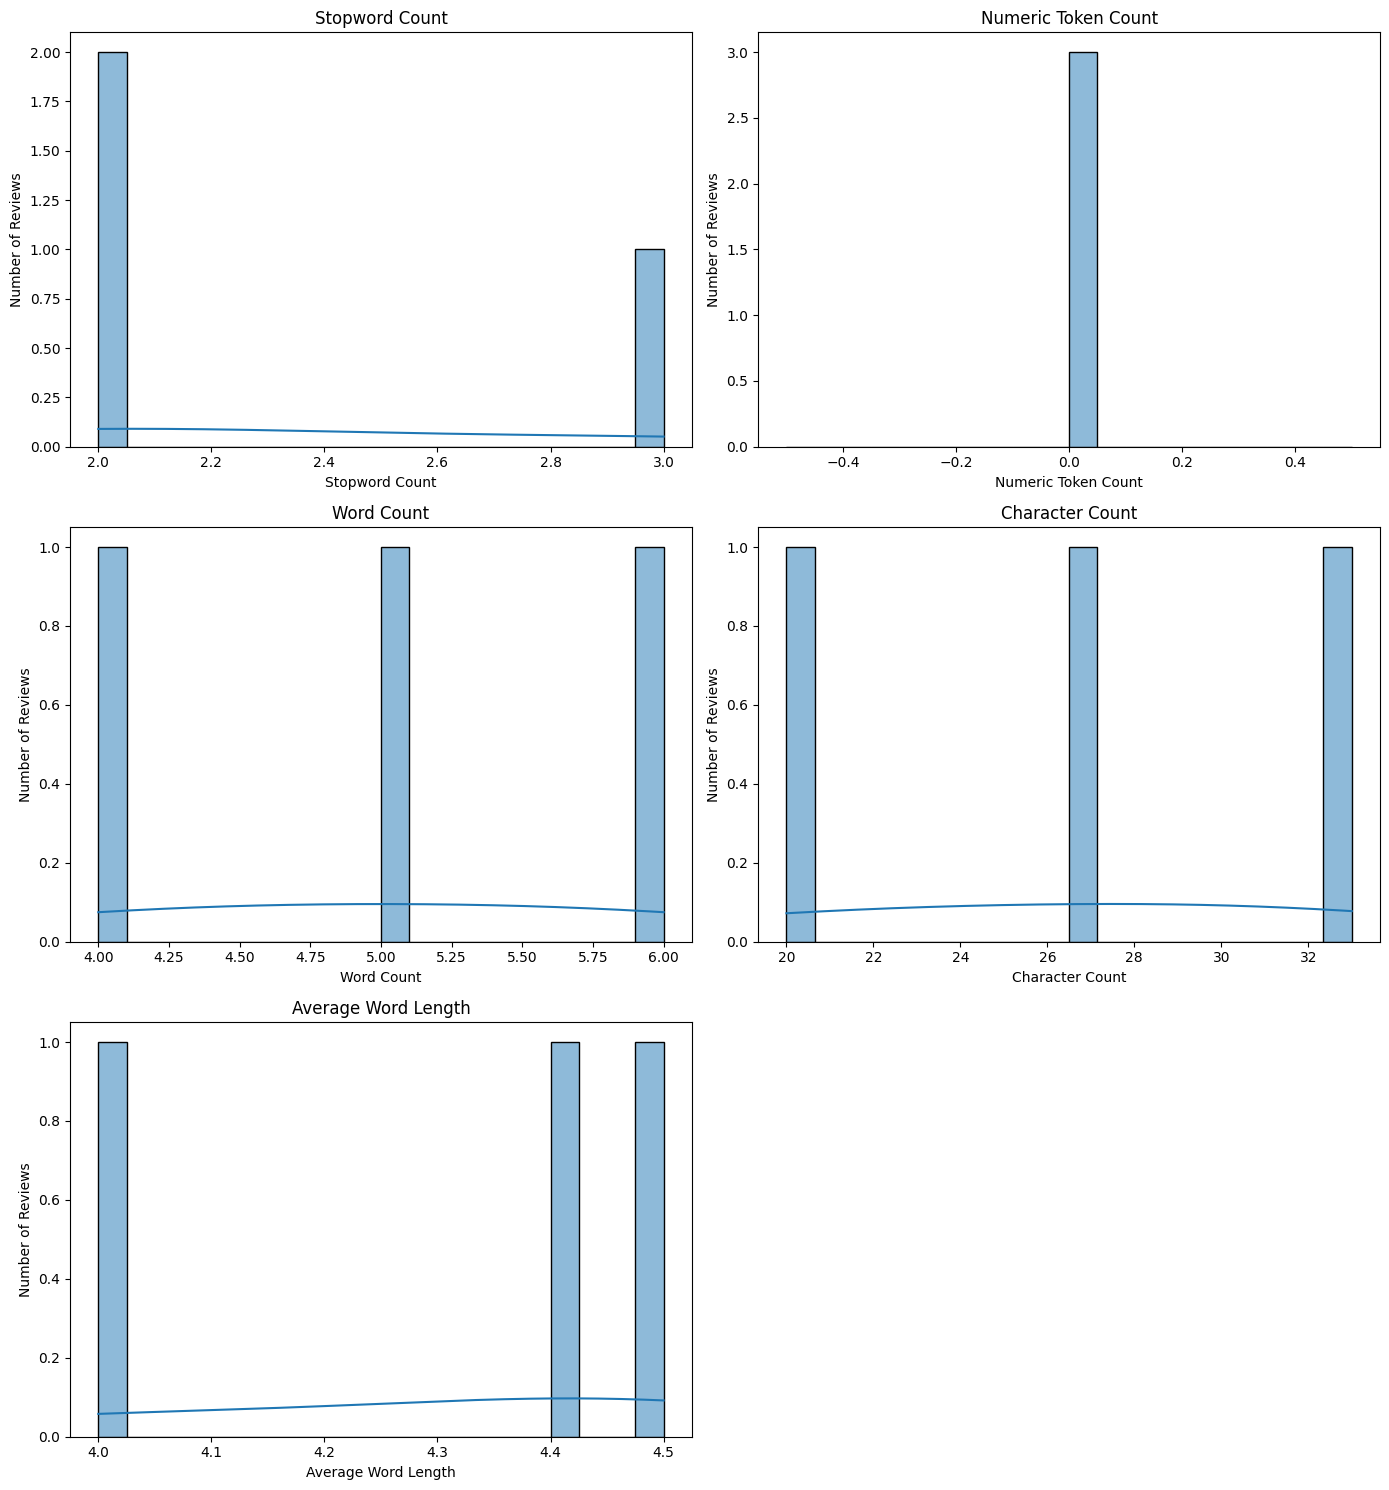

Top 10 stopwords:
[('the', 3), ('is', 2), ('very', 1), ('for', 1)]

Descriptive statistics:
       stopword_count  numeric_count  word_count  character_count  \
count        3.000000            3.0         3.0         3.000000   
mean         2.333333            0.0         5.0        26.666667   
std          0.577350            0.0         1.0         6.506407   
min          2.000000            0.0         4.0        20.000000   
25%          2.000000            0.0         4.5        23.500000   
50%          2.000000            0.0         5.0        27.000000   
75%          2.500000            0.0         5.5        30.000000   
max          3.000000            0.0         6.0        33.000000   

       average_word_length  
count             3.000000  
mean              4.300000  
std               0.264575  
min               4.000000  
25%               4.200000  
50%               4.400000  
75%               4.450000  
max               4.500000  

Total reviews: 3
Statist

In [3]:

import os
import re
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from collections import Counter

nltk.download("stopwords", quiet=True)

folder_path = r"C:\Users\HP\OneDrive\Desktop\reviews.html"
df = pd.read_csv(os.path.join(folder_path, "product_reviews.csv"))

if "Review Text" in df.columns:
    df["review"] = df["Review Text"].fillna("").astype(str)
elif "review" in df.columns:
    df["review"] = df["review"].fillna("").astype(str)
else:
    raise ValueError("Review text column not found: " + str(df.columns.tolist()))

stop_words = set(stopwords.words("english"))

def analyze_review(text):
    tokens = re.findall(r"\b[\w']+\b", text.lower())
    words = re.findall(r"\b[A-Za-z]+\b", text)
    numeric_tokens = re.findall(r"\b\d+(?:\.\d+)?\b", text)

    stopword_tokens = [
        token for token in tokens if token in stop_words
    ]

    return pd.Series({
        "word_count": len(tokens),
        "character_count": len(text),
        "numeric_count": len(numeric_tokens),
        "stopword_count": len(stopword_tokens),
        "average_word_length": (
            sum(len(word) for word in words) / len(words)
            if words else 0
        )
    })

statistics = df["review"].apply(analyze_review)
df = pd.concat([df, statistics], axis=1)

df.to_csv(
    os.path.join(folder_path, "review_statistics.csv"),
    index=False,
    encoding="utf-8-sig"
)

columns = [
    ("stopword_count", "Stopword Count"),
    ("numeric_count", "Numeric Token Count"),
    ("word_count", "Word Count"),
    ("character_count", "Character Count"),
    ("average_word_length", "Average Word Length")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (column, title) in enumerate(columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i],
        bins=20
    )
    axes[i].set_title(title)
    axes[i].set_xlabel(title)
    axes[i].set_ylabel("Number of Reviews")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(
    os.path.join(folder_path, "review_statistics_distributions.png"),
    dpi=300
)
plt.show()

all_tokens = re.findall(
    r"\b[\w']+\b",
    " ".join(df["review"]).lower()
)

stopword_frequency = Counter(
    token for token in all_tokens if token in stop_words
)

print("Top 10 stopwords:")
print(stopword_frequency.most_common(10))

print("\nDescriptive statistics:")
print(df[
    [
        "stopword_count",
        "numeric_count",
        "word_count",
        "character_count",
        "average_word_length"
    ]
].describe())

print("\nTotal reviews:", len(df))
print("Statistics saved successfully.")

In [2]:
%pip install pandas nltk matplotlib seaborn

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 790.3 kB/s eta 0:00:02
   ----------- ---------------------------- 0.5/1.8 MB 790.3 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 706.3 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 706.3 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 658.1 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 658.1 kB/s eta 0:00:02
  


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
